# 2. Churn model: comparison, calibration and threshold analysis

**Goal.** Produce churn probabilities that rank customers well *and* are honest enough to multiply by money. Required baseline: logistic regression plus a tree-based model, with calibration and threshold analysis; stretch: gradient boosting with SHAP.

Numbers in the text were generated for run `20261029T034118630540Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
pd.set_option("display.precision", 4)
run = latest_run()
manifest = read_json(run / "manifest.json")
print("Run:", run.name, "| selected:", manifest["selected_model"], "| threshold:", manifest["threshold"])

Run: 20261029T034118630540Z-88be4b93 | selected: logistic | threshold: 0.4


## Validation design

- 5-fold stratified cross-validation on train tunes each family (average precision as the objective).
- Each tuned model is calibrated with a sigmoid fitted on out-of-fold predictions.
- **Selection on validation** with a rule fixed in advance: AP within 0.01 of best calibrated candidate; Brier within 0.002 of best; prefer simpler.
- Test is scored once, with bootstrap intervals.

In [2]:
validation = pd.read_csv(run / "validation_metrics.csv")
display(validation[["model", "variant", "average_precision", "roc_auc", "brier", "ece", "calibration_slope"]])
display(pd.DataFrame(manifest["best_parameters"]).T[["cv_average_precision", "params"]])

,model,variant,average_precision,roc_auc,brier,ece,calibration_slope
0,dummy,raw,0.2654,0.5000,0.1950,0.0186,NaN
1,logistic,raw,0.6721,0.8579,0.1311,0.0259,1.1230
2,logistic,calibrated,0.6721,0.8579,0.1312,0.0273,1.1439
3,random_forest,raw,0.6693,0.8585,0.1317,0.0330,1.2808
4,random_forest,calibrated,0.6693,0.8585,0.1310,0.0322,1.0724
5,xgboost,raw,0.6712,0.8529,0.1324,0.0329,1.0001
6,xgboost,calibrated,0.6712,0.8529,0.1332,0.0424,1.0701


,cv_average_precision,params
logistic,0.6614,"{'model__class_weight': None, 'model__C': 1}"
random_forest,0.6683,"{'model__n_estimators': 300, 'model__min_sampl..."
xgboost,0.6735,"{'model__subsample': 1.0, 'model__reg_lambda':..."


**Reading.** On validation the calibrated candidates are within a hundredth of each other in average precision, so the rule picks the simplest: **Logistic Regression**.

## Test results with uncertainty

In [3]:
test = pd.read_csv(run / "test_metrics.csv")
display(test[["model", "average_precision", "roc_auc", "brier", "ece", "calibration_slope", "calibration_intercept", "precision", "recall"]])
display(pd.read_csv(run / "bootstrap_intervals.csv"))

,model,average_precision,roc_auc,brier,ece,calibration_slope,calibration_intercept,precision,recall
0,dummy_raw,0.2654,0.5000,0.1950,0.0217,NaN,0.0006,0.0000,0.0000
1,logistic_raw,0.6196,0.8298,0.1423,0.0207,0.9196,-0.0330,0.5589,0.6471
2,logistic_calibrated,0.6196,0.8298,0.1422,0.0192,0.9367,-0.0319,0.5589,0.6471
3,random_forest_raw,0.6208,0.8317,0.1413,0.0199,1.0501,-0.0253,0.5829,0.6203
4,random_forest_calibrated,0.6208,0.8317,0.1436,0.0449,0.9103,-0.0328,0.5904,0.5936
5,xgboost_raw,0.6133,0.8262,0.1435,0.0264,0.8445,-0.0105,0.5652,0.6257
6,xgboost_calibrated,0.6133,0.8262,0.1454,0.0440,0.9304,-0.0060,0.5895,0.5722


,metric,lower_95,upper_95
0,average_precision,0.5671,0.6707
1,roc_auc,0.8068,0.8511
2,brier,0.1318,0.1531
3,log_loss,0.4042,0.4623
4,precision,0.5126,0.6083
5,recall,0.5957,0.6908
6,f1,0.5582,0.6396
7,ece,0.0165,0.0458
8,calibration_slope,0.8283,1.0593
9,calibration_intercept,-0.1720,0.1165


**Interpretation.** PR-AUC 0.620 against a random baseline of 0.265 (the churn rate) and ROC-AUC 0.830. ECE 0.019 means predicted probabilities are on average about 1.9 percentage points from observed churn; slope 0.94 (target 1) and intercept -0.032 (target 0) show no material over- or under-confidence.

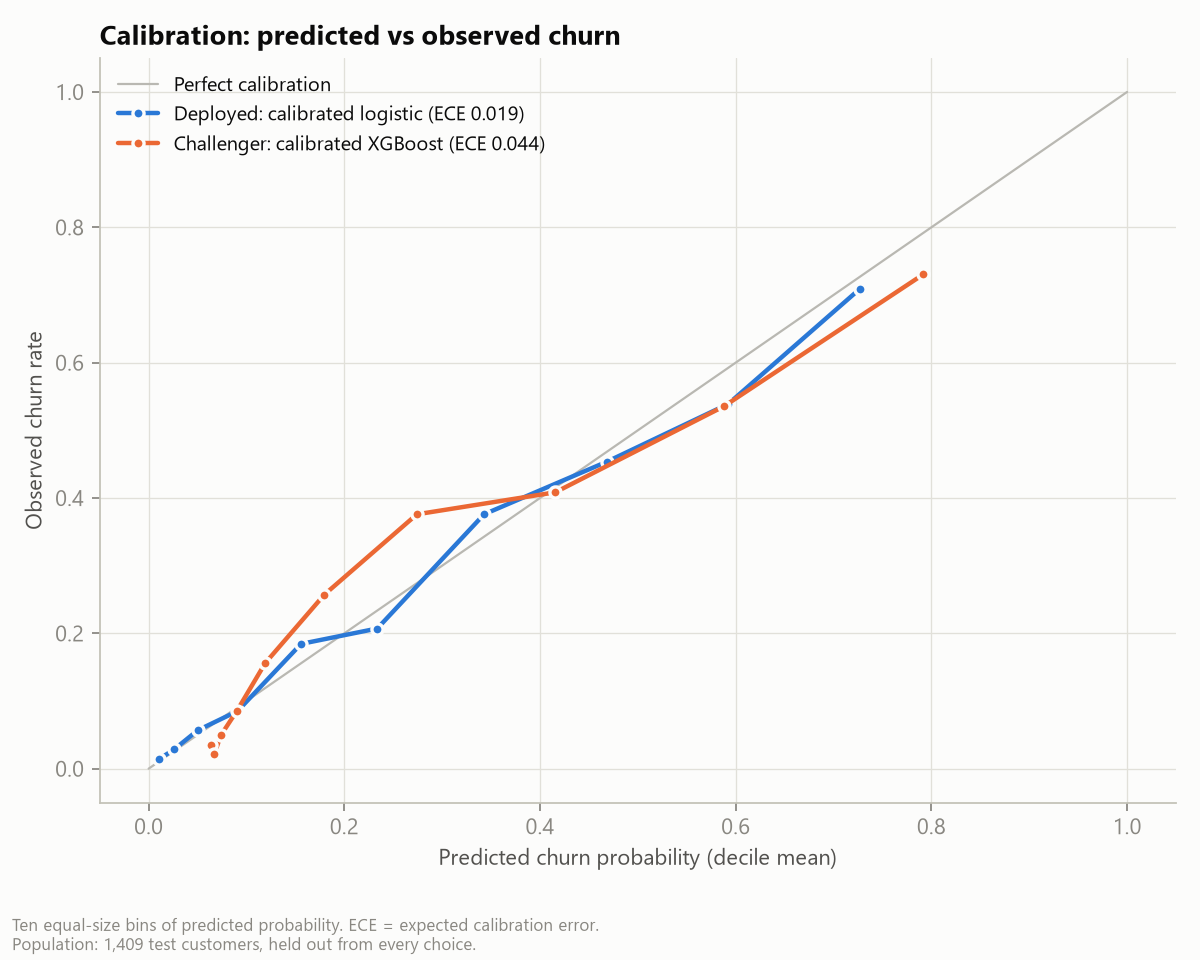

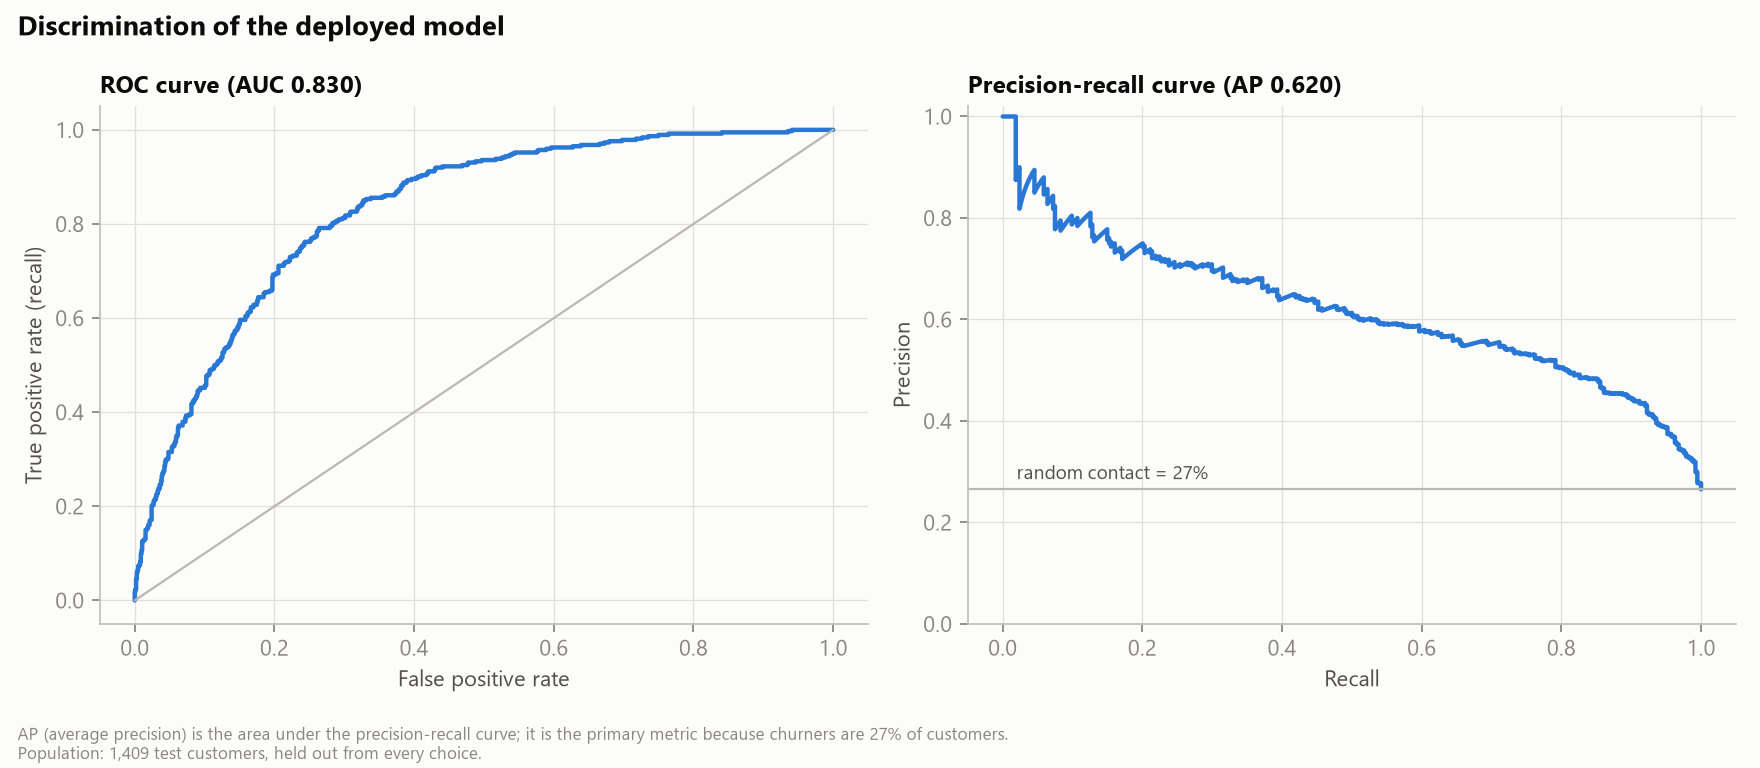

In [4]:
display(Image(filename=str(ROOT / "reports/figures/calibration.png")))
display(Image(filename=str(ROOT / "reports/figures/discrimination.png")))

## Threshold analysis: why one cut-off is not the decision

In [5]:
display(pd.read_csv(run / "threshold_analysis.csv")[["threshold", "precision", "recall", "f1"]].round(3))
display(pd.read_csv(run / "threshold_business.csv"))
display(read_json(run / "break_even.json")["break_even_probability_quantiles"])

,threshold,precision,recall,f1
0,0.05,0.352,0.992,0.519
1,0.10,0.395,0.965,0.561
2,0.15,0.433,0.939,0.592
3,0.20,0.465,0.880,0.609
4,0.25,0.509,0.829,0.631
5,0.30,0.533,0.783,0.634
6,0.35,0.567,0.727,0.637
7,0.40,0.600,0.687,0.641
8,0.45,0.644,0.634,0.639
9,0.50,0.686,0.572,0.624


,rule,customers,cost,expected_net_value,precision,recall
0,Probability >= 0.40 (F1 threshold),433,10825.0,1988.7387,0.5589,0.6471
1,Expected value > 0 (no budget limit),332,8300.0,3202.4365,0.5633,0.5000
2,"Expected value, ranked within the fixed budget",140,3500.0,2340.0182,0.6000,NaN


{'p10': 0.2943546409333618,
 'p25': 0.36409404816988133,
 'p50': 0.5432991995188771,
 'p75': 1.0859460700643673,
 'p90': 1.832907746055055}

**Interpretation.** The F1-best threshold (0.40) treats every customer alike. With value and cost included, the churn probability at which an offer pays off differs by customer, from about 29% for the most valuable to above 100% for the least valuable. Contacting everyone above the F1 threshold spends more and earns less than contacting everyone with positive expected value.

## Gains and drivers

,decile,customers,churn_rate,lift,cumulative_churner_capture
0,1,141,0.7092,2.6719,0.2674
1,2,141,0.5390,2.0306,0.4706
2,3,141,0.4539,1.7100,0.6417
3,4,141,0.3759,1.4161,0.7834
4,5,141,0.2057,0.7749,0.8610
5,6,141,0.1844,0.6947,0.9305
6,7,141,0.0851,0.3206,0.9626
7,8,141,0.0567,0.2138,0.9840
8,9,141,0.0284,0.1069,0.9947
9,10,140,0.0143,0.0538,1.0000


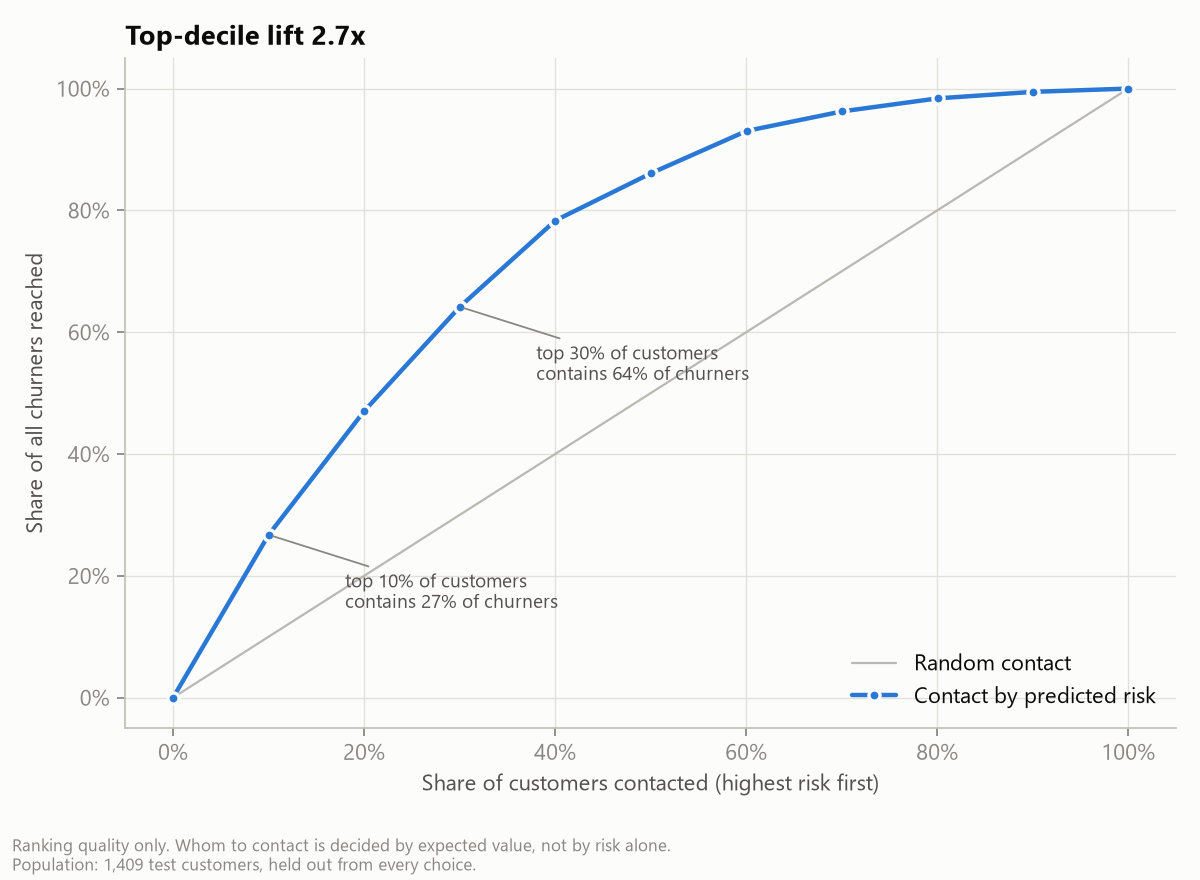

,feature_set,best_C,cv_average_precision,cv_standard_error,encoded_columns,matrix_rank,full_rank,within_one_se,eligible,selected
0,all inputs,1.0,0.6637,0.0145,21,21,True,True,True,False
1,without TotalCharges,1.0,0.6614,0.0130,20,20,True,True,True,True
2,"without TotalCharges, with tenure band",1.0,0.6641,0.0127,22,22,True,True,True,False
3,all inputs with tenure band,1.0,0.6647,0.0137,23,23,True,True,True,False
4,previous design (reference),0.1,0.6649,0.0133,48,24,False,True,False,False


,variable,comparison,odds_ratio
0,Contract,Month-to-month vs Two year,3.66
1,InternetService,Fiber optic vs No,2.90
2,Contract,One year vs Two year,1.79
3,InternetService,DSL vs No,1.67
4,PaymentMethod,Electronic check vs Credit card (automatic),1.53
5,PaperlessBilling,Yes vs No,1.46
6,MultipleLines,Yes vs No,1.29
7,StreamingMovies,Yes vs No,1.17
8,PaymentMethod,Mailed check vs Credit card (automatic),1.15
9,MonthlyCharges,+10 USD a month,1.13


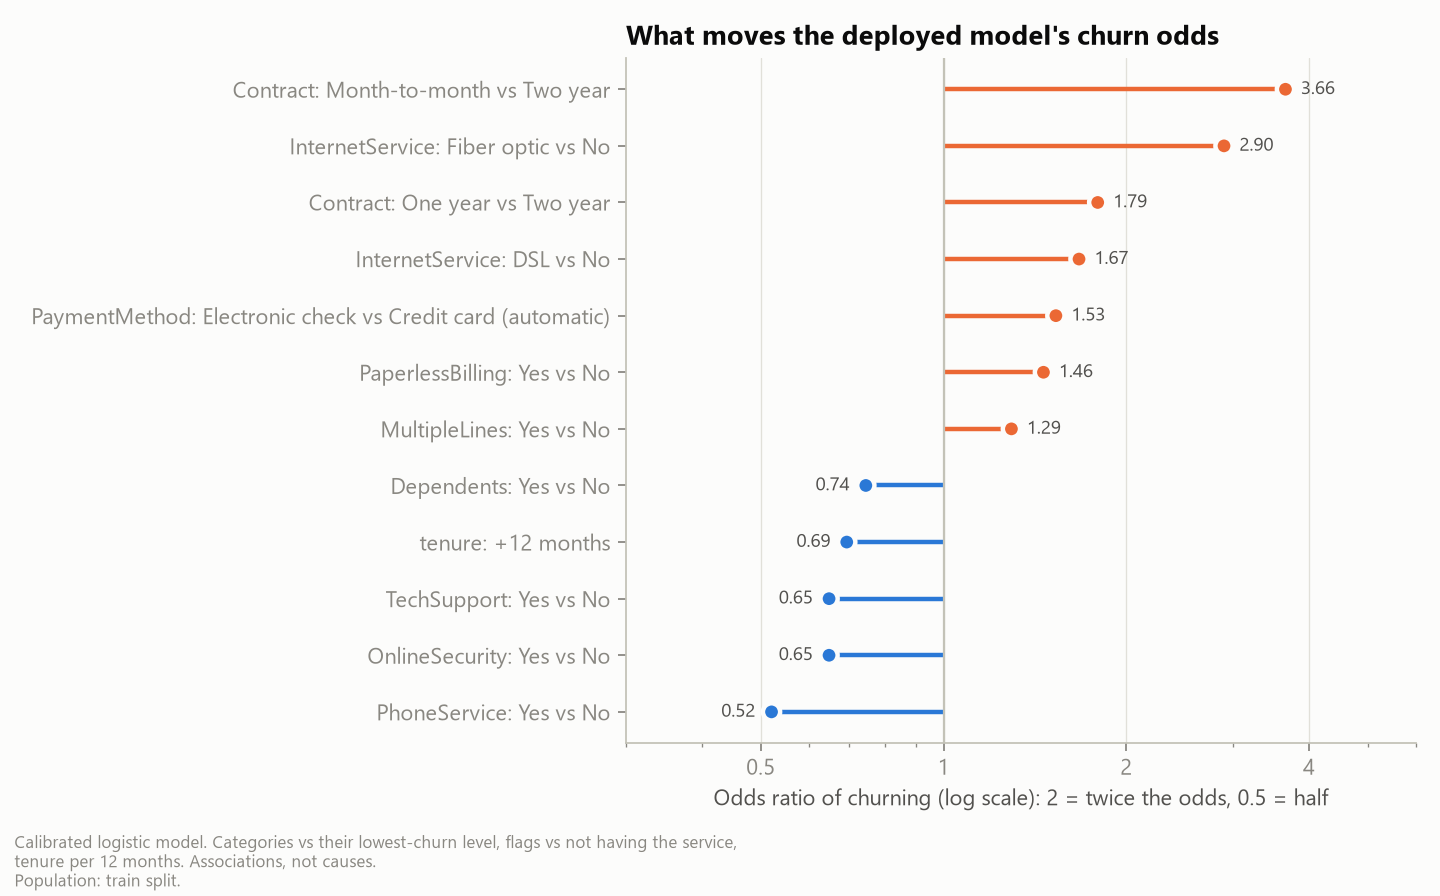

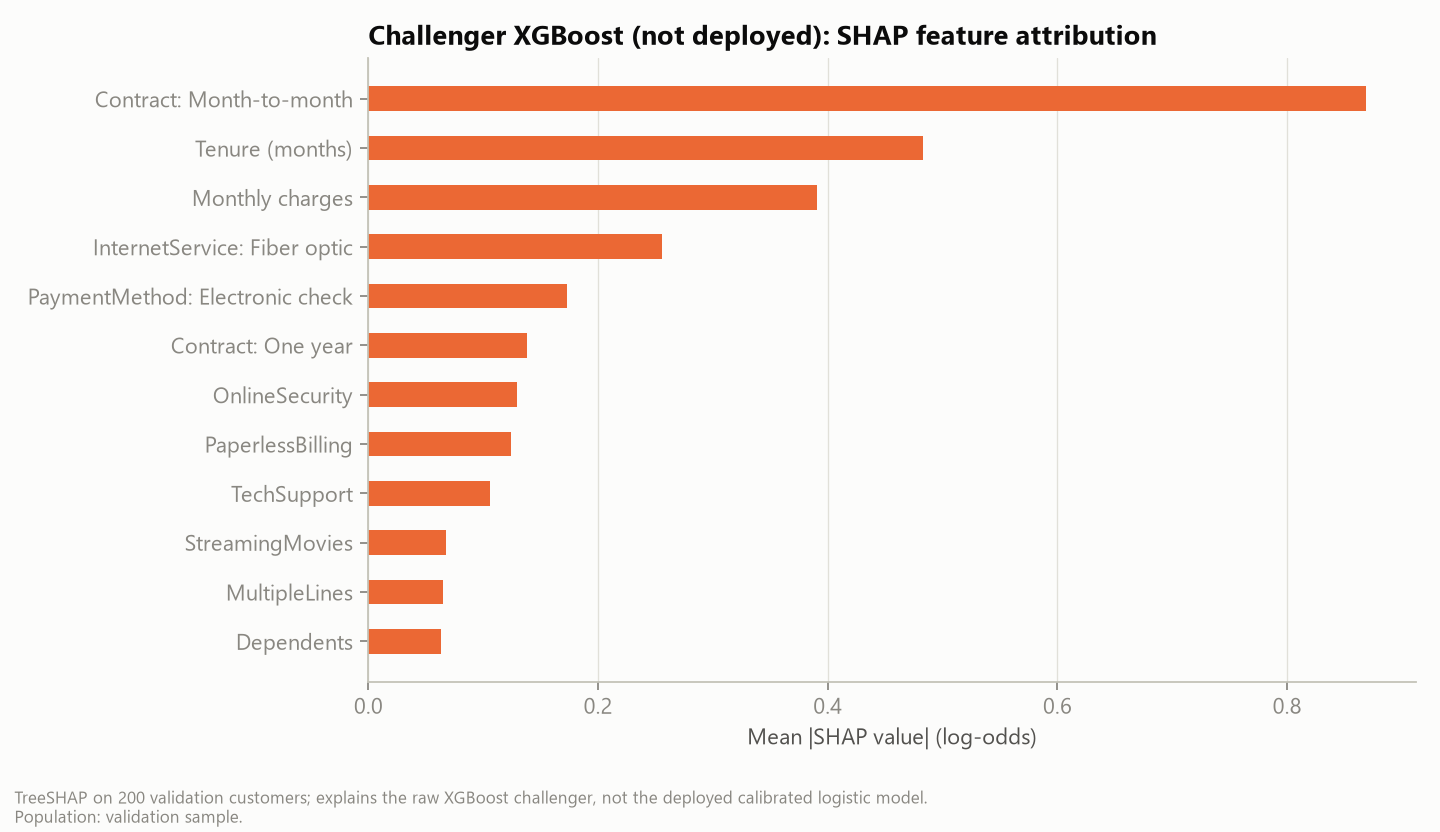

In [6]:
display(pd.read_csv(run / "gains_test.csv")[["decile", "customers", "churn_rate", "lift", "cumulative_churner_capture"]])
display(Image(filename=str(ROOT / "reports/figures/gains.png")))
display(pd.read_csv(run / "feature_ablation.csv").round(4))
display(pd.read_csv(run / "odds_ratios.csv")[["variable", "comparison", "odds_ratio"]].round(2))
display(Image(filename=str(ROOT / "reports/figures/model_drivers.png")))
display(Image(filename=str(ROOT / "reports/figures/shap_challenger.png")))

**Interpretation.** The feature review kept the design with the fewest columns among full-rank sets that rank churners as well as the best (without TotalCharges). Coded against the lowest-churn level, every coefficient is an odds ratio: Contract Month-to-month vs Two year multiplies the odds of churning by 3.66 and InternetService Fiber optic vs No multiplies the odds of churning by 2.90. These are associations in a snapshot, not causes. A points version of the model for the call centre is in [the churn scorecard](../docs/churn-scorecard.md).

## Error analysis

In [7]:
errors = pd.read_csv(run / "segment_errors.csv")
display(errors[["attribute", "group", "n", "small_sample", "average_precision", "roc_auc", "ece", "calibration_slope"]].round(3))
display(pd.read_csv(run / "error_profiles.csv").drop(columns="key").round(3))
display(pd.read_csv(run / "model_profit_check.csv").round(2))

,attribute,group,n,small_sample,average_precision,roc_auc,ece,calibration_slope
0,tenure_segment,developing,204,False,0.533,0.788,0.092,1.090
1,tenure_segment,loyal,774,False,0.435,0.821,0.025,0.899
2,tenure_segment,new,431,False,0.717,0.757,0.048,0.934
3,Contract,Month-to-month,786,False,0.651,0.737,0.037,0.980
4,Contract,One year,284,False,0.343,0.746,0.029,1.047
5,Contract,Two year,339,False,0.167,0.743,0.018,1.110
6,InternetService,DSL,482,False,0.494,0.804,0.028,0.959
7,InternetService,Fiber optic,624,False,0.671,0.748,0.038,0.824
8,InternetService,No,303,False,0.221,0.822,0.028,1.287
9,PaymentMethod,Bank transfer (automatic),303,False,0.658,0.874,0.067,1.160


,outcome,customers,share,mean_probability,mean_tenure,median_monthly_charges,fibre_share,month_to_month_share,echeck_share,senior_share
0,Flagged and left (true positive),242,0.172,0.617,11.640,80.850,0.860,0.988,0.690,0.302
1,Flagged but stayed (false positive),191,0.136,0.560,17.183,81.200,0.801,0.990,0.717,0.272
2,Missed and left (false negative),132,0.094,0.229,30.871,66.775,0.439,0.644,0.341,0.220
3,Not flagged and stayed (true negative),844,0.599,0.111,42.149,55.900,0.243,0.323,0.172,0.101


,population,model,budget,selected_count,expected_net_value,label_based_net,precision_contacted
0,validation,logistic,3500.0,140,2342.29,2247.45,0.64
1,validation,random_forest,3500.0,140,2343.06,2383.05,0.69
2,validation,xgboost,3500.0,140,2450.64,2189.10,0.66
3,test,logistic,3500.0,140,2340.02,1977.06,0.60
4,test,random_forest,3500.0,140,2406.88,1591.28,0.61
5,test,xgboost,3500.0,140,2425.56,1468.45,0.60


**Interpretation.** Ranking inside a segment is weaker than overall (lowest: Contract = Month-to-month, ROC-AUC 0.737), because contract, tenure and internet type are the strongest signals. Calibration is weakest for senior customers, the group the targeting contacts most often. Flagged customers who stayed resemble those who left (99% vs 99% month-to-month); missed churners average 31 months of tenure. In money, the three candidates are within $194 of each other on validation, so the simpler model is a safe choice.

**So what.** The model is good at ranking and its probabilities are trustworthy enough for expected-value arithmetic. It does not tell us which customers an offer would keep; that remains an assumption tested by the pilot.